# Intestine: full experiments with the selected settings

Both collagen-IV images, intensity baselines, joint-selected graph controls and
independently selected spatial comparisons. No configuration search is rerun.

**Planning runtime:** 40–90 minutes on an RTX 4070 SUPER; 1–3 hours on a standard
Colab T4, excluding setup/downloads. The notebook records actual stage times.
In Colab select **Runtime → Change runtime type → T4 GPU**.

Full execution trains 16 CNNs, 36 GraphMAEs and 24 native spatial comparisons.
The supplementary GIN comparison adds 10 GraphMAEs using the same CNN features.
Completed stages resume from `results/intestine`; keep this folder between sessions.

In [1]:
from pathlib import Path
import hashlib
from urllib.request import urlopen

_SETUP = Path("experiment_setup.py")
_SETUP_SHA256 = "6faab2e74f2559b2cc76cbb5b0323215a58e15ab2fb355050c55822de4214175"
if not _SETUP.exists():
    with urlopen("https://raw.githubusercontent.com/moeghaf/mantpy_reproducibility/mantpy-api-v1.1.0/notebooks/experiments/experiment_setup.py", timeout=90) as response:
        _setup_bytes = response.read()
    if hashlib.sha256(_setup_bytes).hexdigest() != _SETUP_SHA256:
        raise RuntimeError("Downloaded setup checksum does not match this notebook.")
    _setup_temp = _SETUP.with_name(_SETUP.name + ".download")
    _setup_temp.write_bytes(_setup_bytes)
    _setup_temp.replace(_SETUP)
if hashlib.sha256(_SETUP.read_bytes()).hexdigest() != _SETUP_SHA256:
    raise RuntimeError("Use the setup file matching this notebook release.")
from experiment_setup import prepare_experiment
ASSETS = prepare_experiment("intestine")


site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1031 09:46:57.104000 54592 torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


Intestine files and matching Mantpy APIs verified.


## Settings and output folder

The joint arm uses the selected CNN and edge-aware GINE configuration with
seeds 0–4. The matched arm uses an independently selected CNN with seeds 0–2;
all four spatial methods receive exactly the same features for each seed.
Both arms use 200 CNN epochs and 200 GraphMAE updates. Cluster numbers are arbitrary.

In [2]:
import json
import time
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import anndata as ad
from scipy import sparse
from scipy.spatial import cKDTree
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from skimage.filters import threshold_multiotsu
import torch
import mantpy as mt
from intestine_helpers import (
    StageStore, PixelScorer, load_images, pixel_annotation, fit_selected_cnn,
    build_selected_graph, calculation_threads, seed_everything, array_sha256,
    plot_patch_labels, score_summary, write_json, environment, release_cuda,
)

SETTINGS = json.loads(Path("intestine_selected.json").read_text())
RESULTS = Path(os.environ.get("MANTPY_RESULTS", "results")) / "intestine"
RESULTS.mkdir(parents=True, exist_ok=True)
CACHE = os.environ.get("MANTPY_CACHE")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE != "cuda":
    raise RuntimeError("Select a T4 GPU runtime before running the full intestine fits.")
NOTEBOOK_STARTED = time.perf_counter()
print(environment())
pd.DataFrame([
    {"image": image, "K": config["k"], "patches": config["expected_nodes"],
     "joint CNN": f'{config["joint"]["cnn_width"]}-wide / {config["joint"]["cnn_readout"]}',
     "matched CNN": config["matched_cnn"]["architecture"]}
    for image, config in SETTINGS["images"].items()
])

{'versions': {'mantpy': '1.0.2', 'torch': '2.13.0+cu130', 'numpy': '2.2.6', 'scipy': '1.16.3', 'scikit-learn': '1.7.2', 'anndata': '0.12.3', 'pybanksy': '1.3.5', 'utag': '0.1.1.dev53+g056cb87ee', 'cellcharter': '0.3.7', 'torchgmm': '0.1.4', 'squidpy': '1.8.2'}, 'cuda': '13.0', 'device': 'NVIDIA GeForce RTX 4070 SUPER'}


,image,K,patches,joint CNN,matched CNN
0,intestine1,5,13376,16-wide / avgpool2,"{'blocks': 3, 'width': 32, 'readout': 'avgpool..."
1,intestine2,4,9449,16-wide / avgpool2,"{'blocks': 3, 'width': 32, 'readout': 'avgpool..."


## Load both images and their original annotations

Image 1 uses its five-layer 32-pixel annotation. Image 2 uses its native
four-class pixel annotation. The loaders verify the public data bundles.

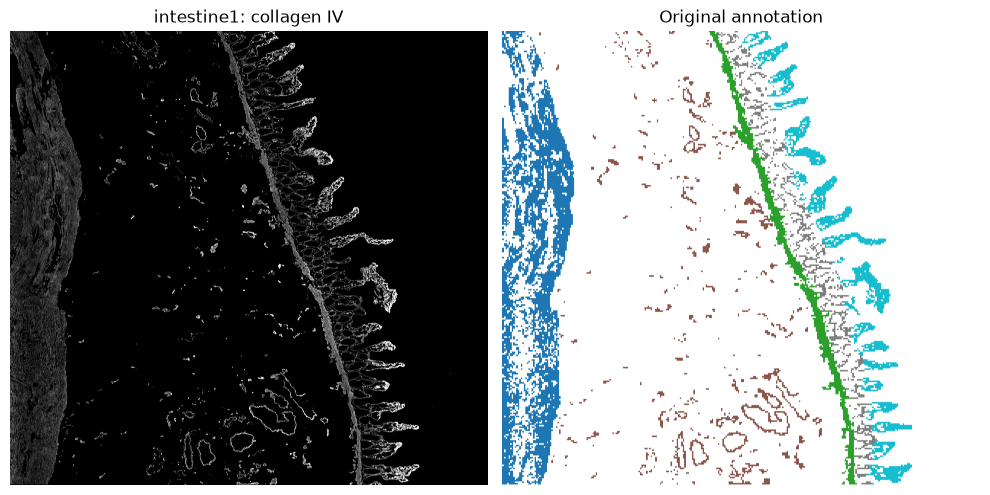

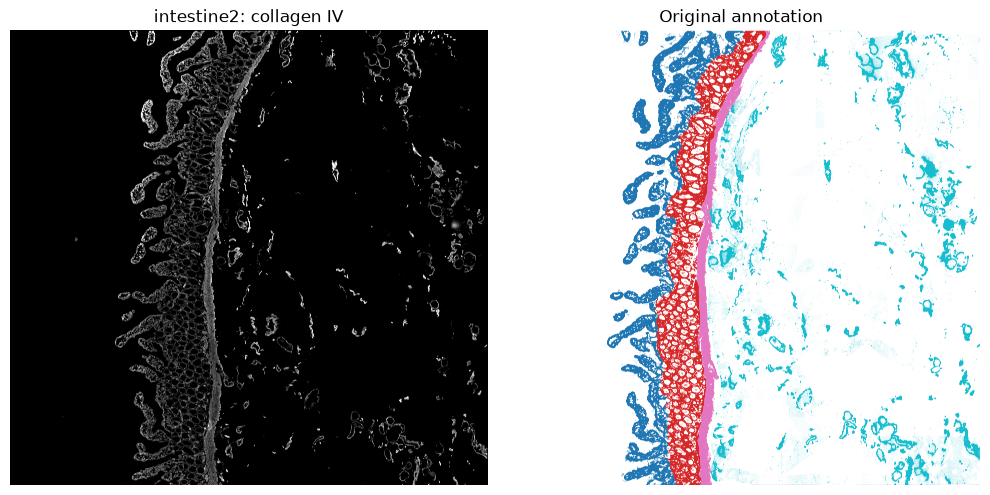

In [3]:
loaded = load_images(cache_dir=CACHE)
for image, item in loaded.items():
    annotation = pixel_annotation(image, item, item["image"].shape)
    figure, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(item["image"], cmap="gray",
                   vmax=SETTINGS["images"][image]["clip"])
    axes[0].set_title(f'{image}: collagen IV')
    axes[1].imshow(np.ma.masked_equal(annotation, 0), cmap="tab10",
                   vmin=1, vmax=SETTINGS["images"][image]["k"])
    axes[1].set_title("Original annotation")
    for axis in axes:
        axis.set_axis_off()
    figure.tight_layout()
    plt.show()
    item["annotation_for_scoring"] = annotation

## Apply the fixed foreground recipe

Clip each image at its positive-pixel 99th percentile and retain 32 × 32
patches above the original patch-mean threshold. The stored pixel threshold
belongs to the original preparation; evaluation uses annotated pixels within
these same foreground patches for every method.

In [4]:
patches, scorers, stores = {}, {}, {}
coverage_rows = []
for image, item in loaded.items():
    config = SETTINGS["images"][image]
    raw = item["image"]
    clip = float(np.percentile(raw[raw > 0].astype(np.float32), 99))
    assert np.isclose(clip, config["clip"]), (image, clip)
    patches[image] = mt.pp.image_ecm_patches(
        raw, channel_names=["ColIV"], patch_size=32, clip_percentile=99,
        pixel_thresholds=[config["pixel_threshold"]],
        patch_thresholds=[config["patch_threshold"]],
        feature_families=("summary",), sample_id=image, random_state=0,
    )
    assert patches[image].n_obs == config["expected_nodes"]
    scorers[image] = PixelScorer(
        patches[image], item["annotation_for_scoring"], config["k"],
    )
    stores[image] = StageStore(
        RESULTS, image, array_sha256(raw) + ":" + array_sha256(patches[image].obs_names.to_numpy(str)),
    )
    pd.DataFrame({"patch_id": patches[image].obs_names,
                  "grid_y": patches[image].obs["grid_y"].to_numpy(),
                  "grid_x": patches[image].obs["grid_x"].to_numpy()}).to_csv(
        RESULTS / image / "patch_ids.csv", index=False,
    )
    coverage_rows.append({
        "image": image, "nodes": patches[image].n_obs,
        "coverage": scorers[image].coverage,
        "annotated_pixels": int(scorers[image].total.sum()),
        "covered_annotated_pixels": int(scorers[image].covered.sum()),
    })
coverage = pd.DataFrame(coverage_rows)
coverage.to_csv(RESULTS / "coverage.csv", index=False)
display(coverage)

site-packages\docrep\decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
site-packages\docrep\decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


,image,nodes,coverage,annotated_pixels,covered_annotated_pixels
0,intestine1,13376,1.000000,13697024,13697024
1,intestine2,9449,0.577696,15231296,8799058


## Pixel and patch-intensity baselines

Pixel K-means fits a fixed sample of two million native pixels, including
background, then labels the complete image. Patch-mean K-means and Multi-Otsu
use the retained patches. All three are scored on the same covered annotation.

In [5]:
score_rows = []
def record_score(image, arm, method, seed, labels, pixel=False):
    score_rows.append({
        "image": image, "arm": arm, "method": method, "seed": seed,
        **scorers[image].score(labels, pixel=pixel),
    })

for image, item in loaded.items():
    config, store = SETTINGS["images"][image], stores[image]
    request = {"k": config["k"], "seed": 0, "n_init": "auto",
               "clip": config["clip"], "sample_pixels": 2_000_000}
    saved = store.load("intensity", "baselines", 0, request)
    if saved is None:
        started = time.perf_counter()
        raw, k, clip = item["image"], config["k"], config["clip"]
        selected = np.sort(np.random.default_rng(0).choice(
            raw.size, min(2_000_000, raw.size), replace=False,
        ))
        sample = (np.minimum(raw.ravel()[selected].astype(np.float32), clip) / clip)[:, None]
        with calculation_threads(8):
            pixel_model = KMeans(n_clusters=k, random_state=0).fit(sample)
        centers = pixel_model.cluster_centers_.ravel()
        order = np.argsort(centers)
        rank = np.empty_like(order)
        rank[order] = np.arange(k)
        pixel_labels = np.empty(raw.shape, dtype=np.uint8)
        for row in range(0, raw.shape[0], 512):
            scaled = np.minimum(raw[row:row + 512].astype(np.float32), clip) / clip
            pixel_labels[row:row + 512] = rank[np.argmin(
                np.abs(scaled[..., None] - centers[None, None, :]), axis=-1,
            )]
        means = patches[image].obsm["image_patches"].reshape(patches[image].n_obs, -1).mean(1)
        with calculation_threads(8):
            patch_labels = KMeans(n_clusters=k, random_state=0).fit_predict(means[:, None])
        thresholds = threshold_multiotsu(means, classes=k)
        otsu_labels = np.digitize(means, thresholds)
        saved = store.save(
            "intensity", "baselines", 0, request, time.perf_counter() - started,
            pixel_labels=pixel_labels, patch_labels=patch_labels,
            otsu_labels=otsu_labels, centers=np.sort(centers), thresholds=thresholds,
        )
    record_score(image, "intensity", "Pixel K-means", 0, saved["pixel_labels"], pixel=True)
    record_score(image, "intensity", "Patch-mean K-means", 0, saved["patch_labels"])
    record_score(image, "intensity", "Multi-Otsu", 0, saved["otsu_labels"])
display(pd.DataFrame(score_rows))

Completed intestine1/intensity/baselines/seed 0: 7.4 s


Completed intestine2/intensity/baselines/seed 0: 4.2 s


,image,arm,method,seed,ARI,macro_F1,full_area_ARI,full_area_macro_F1,coverage,annotated_pixels,covered_annotated_pixels
0,intestine1,intensity,Pixel K-means,0,0.196344,0.341879,0.196344,0.341879,1.000000,13697024,13697024
1,intestine1,intensity,Patch-mean K-means,0,0.229394,0.325816,0.229394,0.325816,1.000000,13697024,13697024
2,intestine1,intensity,Multi-Otsu,0,0.221976,0.322701,0.221976,0.322701,1.000000,13697024,13697024
3,intestine2,intensity,Pixel K-means,0,0.009771,0.300859,0.043446,0.225534,0.577696,15231296,8799058
4,intestine2,intensity,Patch-mean K-means,0,0.017863,0.300561,0.045975,0.226418,0.577696,15231296,8799058
5,intestine2,intensity,Multi-Otsu,0,0.018304,0.304577,0.046223,0.229369,0.577696,15231296,8799058


## Train the shared CNNs

Each image has one joint-selected CNN for each of five seeds and one
independently selected CNN for each of three seeds. The helper implements the
published convolutional architecture, augmentation and NT-Xent loss with
public PyTorch. CNN features are standardised once and shared unchanged.

In [6]:
cnn_results = {}
for image, config in SETTINGS["images"].items():
    windows = np.asarray(patches[image].obsm["image_patches"], dtype=np.float32)
    for arm in ("joint", "matched"):
        if arm == "joint":
            selected = config["joint"]
            architecture = {name: selected["cnn_" + name]
                            for name in ("blocks", "width", "readout", "activation")}
            fixed = {name: selected["cnn_" + name] for name in (
                "latent", "projection", "temperature", "lr", "weight_decay",
                "batch", "epochs", "augment", "standardize",
            )}
        else:
            architecture = config["matched_cnn"]["architecture"]
            fixed = SETTINGS["matched_cnn_fixed"]
        for seed in SETTINGS["seeds"][arm]:
            request = {"architecture": architecture, "training": fixed}
            saved = stores[image].load(arm, "cnn", seed, request)
            if saved is None:
                started = time.perf_counter()
                cnn, features, losses, scaler, updates = fit_selected_cnn(
                    windows, architecture, fixed, seed, device=DEVICE,
                )
                saved = stores[image].save(
                    arm, "cnn", seed, request, time.perf_counter() - started,
                    metadata={"optimizer_updates": updates, "reference_labels_used": False},
                    features=features, losses=losses,
                    scaler_mean=scaler.mean_, scaler_scale=scaler.scale_,
                )
                del cnn, scaler
                release_cuda()
            cnn_results[image, arm, seed] = saved
            kmeans_settings = SETTINGS["kmeans"][arm].copy()
            if arm == "matched":
                kmeans_settings["random_state"] = seed
            with calculation_threads(2 if arm == "joint" else 4):
                labels = KMeans(n_clusters=config["k"], **kmeans_settings).fit_predict(saved["features"])
            saved["labels"] = labels
            record_score(image, arm, "CNN K-means", seed, labels)
            pd.DataFrame({"patch_id": patches[image].obs_names, "cluster": labels}).to_csv(
                RESULTS / image / arm / "cnn" / f"seed_{seed}" / "labels.csv", index=False,
            )
display(pd.DataFrame(score_rows).query("method == 'CNN K-means'"))

GPU available: True (cuda), used: True


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


You are using a CUDA device ('NVIDIA GeForce RTX 4070 SUPER') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


...

site-packages\torch\autograd\graph.py:979: 
UserWarning: adaptive_avg_pool2d_backward_cuda does not have a deterministic implementation, but you set 
'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at 
https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. 
(Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass

site-packages\pytorch_lightning\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
site-packages\pytorch_lightning\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=27` in the `DataLoader` to improve performance.


`Trainer.fit` stopped: `max_epochs=200` reached.


Completed intestine2/matched/cnn/seed 2: 33.6 s


,image,arm,method,seed,ARI,macro_F1,full_area_ARI,full_area_macro_F1,coverage,annotated_pixels,covered_annotated_pixels
6,intestine1,joint,CNN K-means,0,0.445294,0.367725,0.445294,0.367725,1.000000,13697024,13697024
7,intestine1,joint,CNN K-means,1,0.448966,0.360826,0.448966,0.360826,1.000000,13697024,13697024
8,intestine1,joint,CNN K-means,2,0.454362,0.367108,0.454362,0.367108,1.000000,13697024,13697024
9,intestine1,joint,CNN K-means,3,0.454303,0.367034,0.454303,0.367034,1.000000,13697024,13697024
10,intestine1,joint,CNN K-means,4,0.447055,0.369254,0.447055,0.369254,1.000000,13697024,13697024
11,intestine1,matched,CNN K-means,0,0.462657,0.392316,0.462657,0.392316,1.000000,13697024,13697024
12,intestine1,matched,CNN K-means,1,0.482412,0.392088,0.482412,0.392088,1.000000,13697024,13697024
13,intestine1,matched,CNN K-means,2,0.461113,0.395132,0.461113,0.395132,1.000000,13697024,13697024
14,intestine2,joint,CNN K-means,0,0.028063,0.302346,0.049620,0.234649,0.577696,15231296,8799058
15,intestine2,joint,CNN K-means,1,0.026536,0.321196,0.049113,0.241804,0.577696,15231296,8799058


## Full graph, shuffled edges and no-edge control

Joint GraphMAE uses GINE, four 128-unit layers, 50% masking and the selected
graph neighbourhood. Edge attributes are standardised log-distance and
orientation. Shuffling permutes edge destinations while retaining attribute
rows; the no-edge control removes every edge. Both reuse the same CNN.

In [7]:
graph_results = {}
for image, config in SETTINGS["images"].items():
    selected = config["joint"]
    for seed in SETTINGS["seeds"]["joint"]:
        features = cnn_results[image, "joint", seed]["features"]
        for method, control in (("graphmae", None), ("shuffled_edges", "shuffled_edges"),
                                ("no_edges", "no_edges")):
            request = {"selected": selected, "control": control,
                       "features_sha256": array_sha256(features)}
            saved = stores[image].load("joint", method, seed, request)
            if saved is None:
                started = time.perf_counter()
                seed_everything(seed, threads=2)
                data = patches[image].copy()
                del data.obsm["image_patches"]
                data.obsm["X_cnn"] = features
                edges = build_selected_graph(
                    data, selected["neighbours"], selected["continuity_thresh"],
                    control=control, seed=seed,
                )
                model = mt.nn.encode_graphmae(
                    data, graph_key="patch", node_feature_key="X_cnn",
                    key_added="X_graphmae", hidden_dim=selected["gm_width"],
                    n_layers=selected["gm_depth"], encoder=selected["edge_use"],
                    decoder="graphmae_remask", norm="layernorm",
                    mask_ratio=selected["gm_mask"], mitigation="jk",
                    max_epochs=selected["gm_updates"], lr=selected["gm_lr"],
                    weight_decay=selected["gm_weight_decay"], recon_loss="scaled_cosine",
                    standardize=selected["gm_standardize"], random_state=seed,
                    accelerator=DEVICE, enable_progress_bar=True,
                )
                embedding = np.asarray(data.obsm["X_graphmae"], dtype=np.float32)
                optimizer_updates = model.optimizer_updates
                losses = np.asarray(model.history["train_loss"])
                with calculation_threads(2):
                    labels = KMeans(n_clusters=config["k"], **SETTINGS["kmeans"]["joint"]).fit_predict(embedding)
                saved = stores[image].save(
                    "joint", method, seed, request, time.perf_counter() - started,
                    metadata={"directed_edges": edges, "reference_labels_used": False,
                              "optimizer_updates": optimizer_updates},
                    embedding=embedding, labels=labels, losses=losses,
                )
                del data, model
                release_cuda()
            graph_results[image, "joint", method, seed] = saved
            record_score(image, "joint", method, seed, saved["labels"])

GraphMAE:   0%|          | 0/200 [00:00<?, ?epoch/s]

GraphMAE:   0%|          | 1/200 [00:01<03:51,  1.16s/epoch, loss=1.0657]

GraphMAE:   1%|          | 2/200 [00:02<03:19,  1.01s/epoch, loss=0.9189]

GraphMAE:   2%|▏         | 3/200 [00:02<02:24,  1.36epoch/s, loss=0.8618]

GraphMAE:   2%|▏         | 4/200 [00:02<01:58,  1.65epoch/s, loss=0.8405]

...

GraphMAE:  88%|████████▊ | 177/200 [00:02<00:00, 78.60epoch/s, loss=0.8977]

GraphMAE:  92%|█████████▎| 185/200 [00:02<00:00, 77.56epoch/s, loss=0.8963]

GraphMAE:  96%|█████████▋| 193/200 [00:02<00:00, 75.76epoch/s, loss=0.8945]

GraphMAE: 100%|██████████| 200/200 [00:02<00:00, 69.59epoch/s, loss=0.8894]

Completed intestine2/joint/no_edges/seed 4: 6.2 s


## Native spatial comparisons

Coordinates are converted to micrometres. BANKSY and UTAG retain their native
neighbourhood transformations, followed by the specified PCA and K-means.
CellCharter uses its native mean neighbourhood aggregation and Gaussian
mixture clustering. Its published fits use CPU.

In [8]:
from banksy.initialize_banksy import initialize_banksy
from banksy.embed_banksy import generate_banksy_matrix
from utag import utag
import cellcharter as cc
import squidpy as sq

def fit_native_comparison(image, features, method, config, seed, n_init):
    seed_everything(seed, threads=4)
    data = ad.AnnData(
        X=features.copy(),
        obs=pd.DataFrame({"sample_id": pd.Categorical([image] * len(features))},
                         index=patches[image].obs_names.copy()),
    )
    data.obsm["spatial"] = np.asarray(patches[image].obsm["spatial"]) * SETTINGS["pixel_size_um"]
    xy, k = data.obsm["spatial"], SETTINGS["images"][image]["k"]
    guard = SETTINGS["directed_edge_guard"]
    with calculation_threads(4):
        if method == "banksy":
            edges = len(features) * config["k"]
            if edges > guard:
                raise RuntimeError("Selected BANKSY setting exceeds the published edge guard.")
            data.obs["x"], data.obs["y"] = xy[:, 0], xy[:, 1]
            banksy = initialize_banksy(
                data, coord_keys=("x", "y", "spatial"),
                num_neighbours=config["k"], nbr_weight_decay="scaled_gaussian",
                max_m=config["max_m"], plt_edge_hist=False, plt_nbr_weights=False,
                plt_agf_angles=False, plt_theta=False,
            )
            banksy, _ = generate_banksy_matrix(
                data, banksy, lambda_list=[config["lambda"]],
                max_m=config["max_m"], verbose=False,
            )
            transformed = banksy["scaled_gaussian"][config["lambda"]]["adata"].X
            transformed = transformed.toarray() if sparse.issparse(transformed) else np.asarray(transformed)
            embedding = PCA(n_components=config["pca"], random_state=seed).fit_transform(
                transformed.astype(np.float32),
            )
            labels = KMeans(n_clusters=k, n_init=n_init, random_state=seed).fit_predict(embedding)
        elif method == "utag":
            edges = int(cKDTree(xy).query_ball_point(
                xy, config["radius_um"], return_length=True,
            ).sum())
            if edges > guard:
                raise RuntimeError("Selected UTAG setting exceeds the published edge guard.")
            transformed = utag(
                data, slide_key=None, max_dist=config["radius_um"],
                normalization_mode=config["normalization"],
                apply_clustering=False, parallel=False,
            ).X
            transformed = transformed.toarray() if sparse.issparse(transformed) else np.asarray(transformed)
            embedding = PCA(n_components=config["pca"], random_state=seed).fit_transform(
                transformed.astype(np.float32),
            )
            labels = KMeans(n_clusters=k, n_init=n_init, random_state=seed).fit_predict(embedding)
        else:
            if config["graph"] == "native_knn6":
                sq.gr.spatial_neighbors(
                    data, coord_type="generic", n_neighs=6, library_key="sample_id",
                )
                connectivity = "spatial_connectivities"
            else:
                neighbours = int(config["graph"].split("_k")[1])
                geometry = patches[image].copy()
                del geometry.obsm["image_patches"]
                mt.gr.build_patch_graph(
                    geometry, k=neighbours, continuity_thresh=.25,
                    continuity_samples=6, key_added="patch",
                )
                edges = np.asarray(geometry.uns["patch"]["edge_index"])
                connectivity = "mantpy_connectivities"
                data.obsp[connectivity] = sparse.csr_matrix(
                    (np.ones(edges.shape[1]), (edges[0], edges[1])),
                    shape=(len(features), len(features)),
                )
                del geometry
            edges = int(data.obsp[connectivity].nnz)
            if edges > guard:
                raise RuntimeError("Selected CellCharter setting exceeds the published edge guard.")
            cc.gr.aggregate_neighbors(
                data, n_layers=config["hops"], aggregations="mean",
                connectivity_key=connectivity, sample_key="sample_id",
            )
            estimator = cc.tl.Cluster(
                n_clusters=k, covariance_type="full", random_state=seed,
                trainer_params={"accelerator": "cpu"},
            )
            estimator.fit(data)
            labels = np.asarray(estimator.predict(data), dtype=np.int64)
            embedding = np.asarray(data.obsm["X_cellcharter"])
    assert labels.shape == (len(features),) and np.isfinite(embedding).all()
    return labels, np.asarray(embedding, dtype=np.float32), edges

### Published default comparisons

Seed-0 joint CNN: BANKSY uses 15 neighbours, λ=0.2 and PCA-20; UTAG uses a
20 µm radius and PCA-10; CellCharter uses six neighbours and three hops.
These defaults use K-means `n_init="auto"`. CNN Ward is also included.

In [9]:
native_results = {}
for image, config in SETTINGS["images"].items():
    features = cnn_results[image, "joint", 0]["features"]
    default_configurations = {
        "banksy": {"k": 15, "lambda": .2, "max_m": 1, "pca": 20},
        "utag": {"radius_um": 20., "pca": 10, "normalization": "l1_norm"},
        "cellcharter": {"graph": "native_knn6", "hops": 3},
    }
    for method, selected in default_configurations.items():
        request = {"config": selected, "n_init": "auto",
                   "features_sha256": array_sha256(features)}
        saved = stores[image].load("defaults", method, 0, request)
        if saved is None:
            started = time.perf_counter()
            labels, embedding, edges = fit_native_comparison(
                image, features, method, selected, 0, n_init="auto",
            )
            saved = stores[image].save(
                "defaults", method, 0, request, time.perf_counter() - started,
                metadata={"directed_edges": edges, "reference_labels_used": False},
                labels=labels, embedding=embedding,
            )
        native_results[image, "defaults", method, 0] = saved
        record_score(image, "defaults", method, 0, saved["labels"])
    request = {"linkage": "ward", "standardize": True,
               "features_sha256": array_sha256(features)}
    saved = stores[image].load("defaults", "cnn_ward", 0, request)
    if saved is None:
        started = time.perf_counter()
        labels = AgglomerativeClustering(n_clusters=config["k"], linkage="ward").fit_predict(
            StandardScaler().fit_transform(features).astype(np.float32),
        )
        saved = stores[image].save(
            "defaults", "cnn_ward", 0, request, time.perf_counter() - started, labels=labels,
        )
    record_score(image, "defaults", "CNN Ward", 0, saved["labels"])
display(pd.DataFrame(score_rows).query("arm == 'defaults'"))


Median distance to closest cell = 12.07806396484375

---- Ran median_dist_to_nearest_neighbour in 0.04 s ----

---- Ran generate_spatial_distance_graph in 0.10 s ----



---- Ran row_normalize in 0.06 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.48 s ----

---- Ran generate_spatial_distance_graph in 0.14 s ----



---- Ran theta_from_spatial_graph in 0.12 s ----



---- Ran row_normalize in 0.07 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.63 s ----

Decay Type: scaled_gaussian
Weights Object: {'weights': {0: <Compressed Sparse Row sparse matrix of dtype 'float64'
	with 200640 stored elements and shape (13376, 13376)>, 1: <Compressed Sparse Row sparse matrix of dtype 'complex128'
	with 401280 stored elements and shape (13376, 13376)>}}

Nbr matrix | Mean: -0.01 | Std: 0.5
Size of Nbr | Shape: (13376, 96)
Top 3 entries of Nbr Mat:

[[ 0.50427805 -0.21308155  0.15201599]
 [ 0.44128439 -0.27269436  0.16348742]
 [ 0.56292056 -0.0965198   0.09079774]]



AGF matrix | Mean: 0.2 | Std: 0.16
Size of AGF mat (m = 1) | Shape: (13376, 96)
Top entries of AGF:
[[0.45947633 0.25474664 0.20582952]
 [0.33051136 0.19060222 0.16798727]
 [0.31067861 0.16713477 0.13036272]]
Ran 'Create BANKSY Matrix' in 0.01 mins


...

TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Completed intestine2/defaults/cellcharter/seed 0: 22.1 s


Completed intestine2/defaults/cnn_ward/seed 0: 3.1 s


,image,arm,method,seed,ARI,macro_F1,full_area_ARI,full_area_macro_F1,coverage,annotated_pixels,covered_annotated_pixels
52,intestine1,defaults,banksy,0,0.515103,0.387416,0.515103,0.387416,1.000000,13697024,13697024
53,intestine1,defaults,utag,0,0.574781,0.426515,0.574781,0.426515,1.000000,13697024,13697024
54,intestine1,defaults,cellcharter,0,0.670931,0.479687,0.670931,0.479687,1.000000,13697024,13697024
55,intestine1,defaults,CNN Ward,0,0.444559,0.339242,0.444559,0.339242,1.000000,13697024,13697024
56,intestine2,defaults,banksy,0,0.030089,0.247421,0.049551,0.180144,0.577696,15231296,8799058
57,intestine2,defaults,utag,0,0.060568,0.356819,0.060789,0.268415,0.577696,15231296,8799058
58,intestine2,defaults,cellcharter,0,0.088633,0.329918,0.070616,0.230831,0.577696,15231296,8799058
59,intestine2,defaults,CNN Ward,0,0.037752,0.297062,0.052445,0.238912,0.577696,15231296,8799058


### Independently selected matched comparisons

These are the deposited per-method selections, made without reference
annotations. The twelve candidate settings were searched in the paper;
this notebook refits only the selected setting for each method.

In [10]:
selected_rows = []
for image, config in SETTINGS["images"].items():
    for method, record in config["matched_methods"].items():
        selected_rows.append({
            "image": image, "method": method,
            "selection_index": record["index"], "config": record["config"],
        })
display(pd.DataFrame(selected_rows))

for image, config in SETTINGS["images"].items():
    for seed in SETTINGS["seeds"]["matched"]:
        features = cnn_results[image, "matched", seed]["features"]
        for method in ("graphmae", "banksy", "utag", "cellcharter"):
            selected = config["matched_methods"][method]["config"]
            request = {"selected": selected, "features_sha256": array_sha256(features),
                       "n_init": 10, "training": SETTINGS["matched_graphmae_fixed"] if method == "graphmae" else None}
            saved = stores[image].load("matched", method, seed, request)
            if saved is None:
                started = time.perf_counter()
                if method == "graphmae":
                    seed_everything(seed, threads=4)
                    data = patches[image].copy()
                    del data.obsm["image_patches"]
                    data.obsm["X_cnn"] = features
                    edges = build_selected_graph(data, selected["k"])
                    if edges > SETTINGS["directed_edge_guard"]:
                        raise RuntimeError("Selected GraphMAE setting exceeds the published edge guard.")
                    model = mt.nn.encode_graphmae(
                        data, graph_key="patch", node_feature_key="X_cnn",
                        key_added="X_graphmae", n_layers=selected["depth"],
                        mask_ratio=selected["mask"], random_state=seed,
                        accelerator=DEVICE, enable_progress_bar=True,
                        **SETTINGS["matched_graphmae_fixed"],
                    )
                    embedding = np.asarray(data.obsm["X_graphmae"], dtype=np.float32)
                    optimizer_updates = model.optimizer_updates
                    losses = np.asarray(model.history["train_loss"])
                    with calculation_threads(4):
                        labels = KMeans(n_clusters=config["k"], n_init=10,
                                        random_state=seed).fit_predict(embedding)
                    del data, model
                    release_cuda()
                else:
                    labels, embedding, edges = fit_native_comparison(
                        image, features, method, selected, seed, n_init=10,
                    )
                    losses = np.empty(0)
                saved = stores[image].save(
                    "matched", method, seed, request, time.perf_counter() - started,
                    metadata={"directed_edges": edges, "reference_labels_used": False,
                              "optimizer_updates": optimizer_updates if method == "graphmae" else None},
                    labels=labels, embedding=embedding, losses=losses,
                )
            if method == "graphmae":
                graph_results[image, "matched", method, seed] = saved
            else:
                native_results[image, "matched", method, seed] = saved
            record_score(image, "matched", method, seed, saved["labels"])

,image,method,selection_index,config
0,intestine1,graphmae,9,"{'k': 240, 'depth': 2, 'mask': 0.75}"
1,intestine1,banksy,9,"{'k': 240, 'lambda': 0.4, 'max_m': 1, 'pca': 20}"
2,intestine1,utag,6,"{'radius_um': 232.3265075275914, 'pca': 10, 'n..."
3,intestine1,cellcharter,8,"{'graph': 'mantpy_k120', 'hops': 3}"
4,intestine2,graphmae,1,"{'k': 80, 'depth': 2, 'mask': 0.75}"
5,intestine2,banksy,7,"{'k': 160, 'lambda': 0.8, 'max_m': 1, 'pca': 20}"
6,intestine2,utag,6,"{'radius_um': 336.45637576578406, 'pca': 10, '..."
7,intestine2,cellcharter,2,"{'graph': 'native_knn6', 'hops': 3}"


GraphMAE:   0%|          | 0/200 [00:00<?, ?epoch/s]

GraphMAE:   0%|          | 1/200 [00:00<01:16,  2.60epoch/s, loss=0.9974]

GraphMAE:   2%|▏         | 3/200 [00:00<00:33,  5.85epoch/s, loss=0.6740]

GraphMAE:   2%|▎         | 5/200 [00:00<00:25,  7.58epoch/s, loss=0.5552]

...

site-packages\rich\live.py:260: UserWarning: install "ipywidgets" 
for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

GPU available: True (cuda), used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Completed intestine2/matched/cellcharter/seed 2: 30.5 s


## Compare agreement and inspect representative maps

ARI is invariant to cluster numbering. Macro-F1 uses one-to-one cluster/class
matching. Full-area scores include one unassigned label outside the same
foreground support for every method. Means and sample SDs summarise seeds;
single-fit baselines have no seed SD.

,image,arm,method,ARI_mean,ARI_std,macro_F1_mean,macro_F1_std,full_area_ARI_mean,full_area_ARI_std,full_area_macro_F1_mean,full_area_macro_F1_std,seeds
0,intestine1,defaults,CNN Ward,0.445,NaN,0.339,NaN,0.445,NaN,0.339,NaN,1
1,intestine1,defaults,banksy,0.515,NaN,0.387,NaN,0.515,NaN,0.387,NaN,1
2,intestine1,defaults,cellcharter,0.671,NaN,0.480,NaN,0.671,NaN,0.480,NaN,1
3,intestine1,defaults,utag,0.575,NaN,0.427,NaN,0.575,NaN,0.427,NaN,1
4,intestine1,intensity,Multi-Otsu,0.222,NaN,0.323,NaN,0.222,NaN,0.323,NaN,1
5,intestine1,intensity,Patch-mean K-means,0.229,NaN,0.326,NaN,0.229,NaN,0.326,NaN,1
6,intestine1,intensity,Pixel K-means,0.196,NaN,0.342,NaN,0.196,NaN,0.342,NaN,1
7,intestine1,joint,CNN K-means,0.450,0.004,0.366,0.003,0.450,0.004,0.366,0.003,5
8,intestine1,joint,graphmae,0.886,0.029,0.851,0.109,0.886,0.029,0.851,0.109,5
9,intestine1,joint,no_edges,0.225,0.031,0.347,0.022,0.225,0.031,0.347,0.022,5


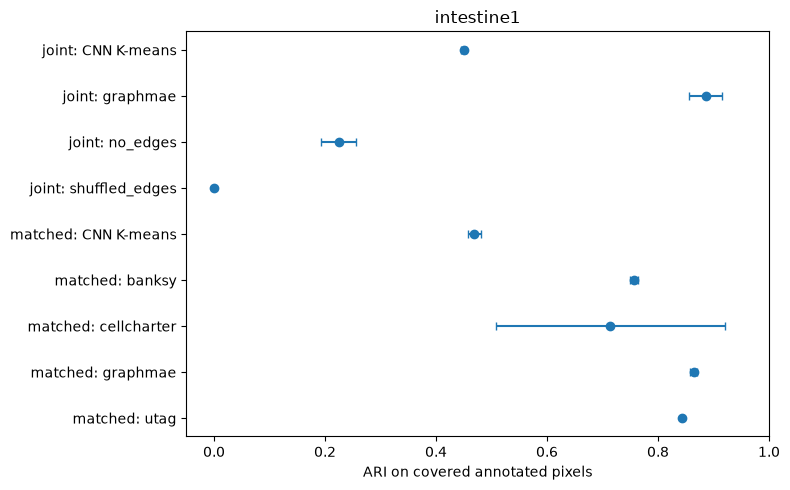

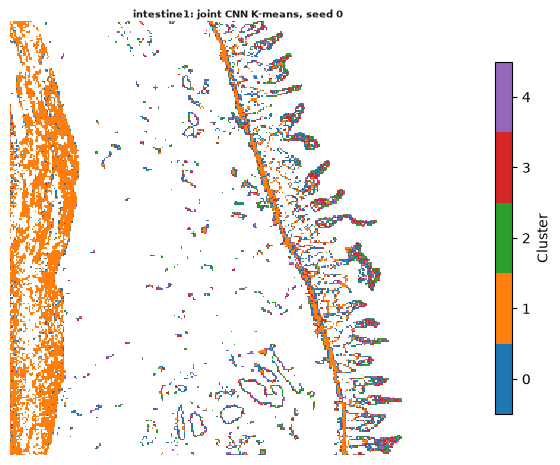

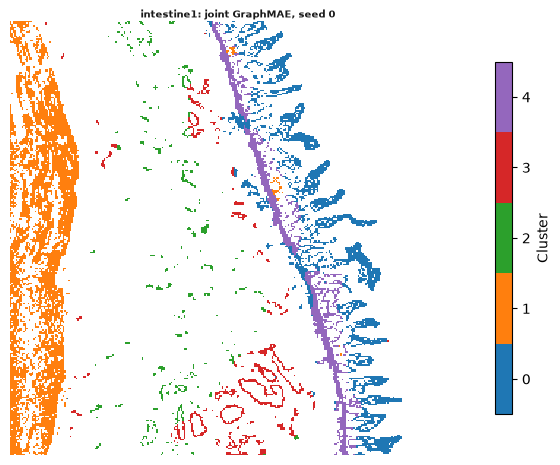

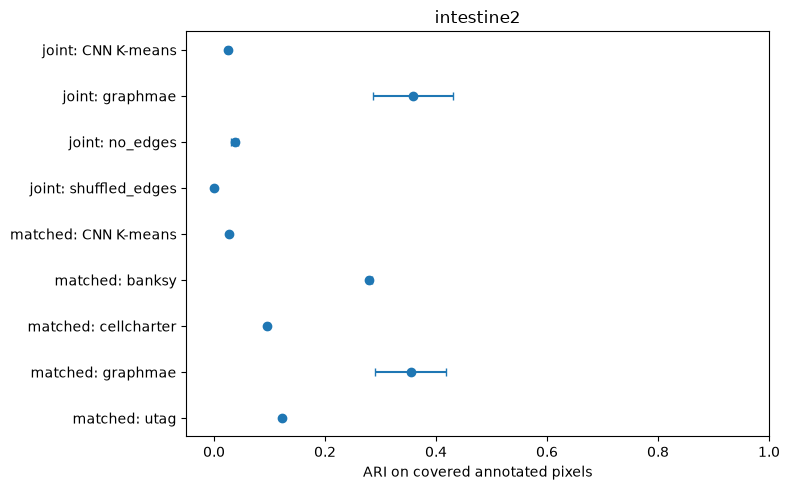

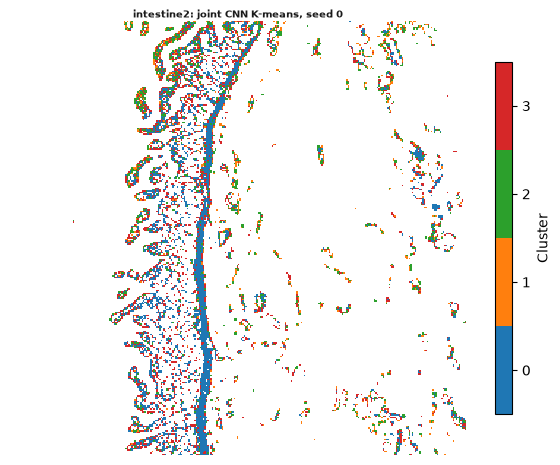

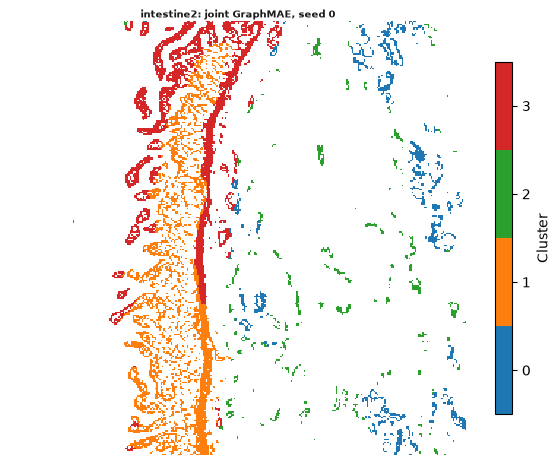

In [11]:
scores, summary = score_summary(score_rows)
display(summary.round(3))
for image in SETTINGS["images"]:
    comparison = summary.query("image == @image and arm in ['joint', 'matched']")
    figure, axis = plt.subplots(figsize=(8, 5))
    positions = np.arange(len(comparison))
    axis.errorbar(comparison["ARI_mean"], positions,
                  xerr=comparison["ARI_std"].fillna(0), fmt="o", capsize=3)
    axis.set_yticks(positions, comparison["arm"] + ": " + comparison["method"])
    axis.set(xlabel="ARI on covered annotated pixels", title=image, xlim=(-.05, 1))
    axis.invert_yaxis()
    figure.tight_layout()
    figure.savefig(RESULTS / image / "agreement.png", dpi=160)
    plt.show()
    plot_patch_labels(
        patches[image], cnn_results[image, "joint", 0]["labels"],
        f"{image}: joint CNN K-means, seed 0", SETTINGS["images"][image]["k"],
        save=RESULTS / image / "cnn_seed0.png",
    )
    plot_patch_labels(
        patches[image], graph_results[image, "joint", "graphmae", 0]["labels"],
        f"{image}: joint GraphMAE, seed 0", SETTINGS["images"][image]["k"],
        save=RESULTS / image / "graphmae_seed0.png",
    )

## Supplementary: GIN versus GINE at the joint-selected setting

Refit GIN with the same CNN features, topology and training settings for all
five seeds. GINE is already fitted above. GIN ignores the edge attributes.

In [12]:
for image, config in SETTINGS["images"].items():
    selected = config["joint"]
    for seed in SETTINGS["seeds"]["joint"]:
        features = cnn_results[image, "joint", seed]["features"]
        request = {"selected": selected, "encoder": "gin",
                   "features_sha256": array_sha256(features)}
        saved = stores[image].load("supplementary", "gin", seed, request)
        if saved is None:
            started = time.perf_counter()
            seed_everything(seed, threads=2)
            data = patches[image].copy()
            del data.obsm["image_patches"]
            data.obsm["X_cnn"] = features
            edges = build_selected_graph(data, selected["neighbours"])
            model = mt.nn.encode_graphmae(
                data, graph_key="patch", node_feature_key="X_cnn", key_added="X_graphmae",
                hidden_dim=128, n_layers=4, encoder="gin", decoder="graphmae_remask",
                norm="layernorm", mask_ratio=.5, mitigation="jk", max_epochs=200,
                lr=.001, weight_decay=.0001, recon_loss="scaled_cosine",
                standardize=False, random_state=seed, accelerator=DEVICE,
                enable_progress_bar=True,
            )
            embedding = np.asarray(data.obsm["X_graphmae"], dtype=np.float32)
            optimizer_updates = model.optimizer_updates
            with calculation_threads(2):
                labels = KMeans(n_clusters=config["k"], **SETTINGS["kmeans"]["joint"]).fit_predict(embedding)
            saved = stores[image].save(
                "supplementary", "gin", seed, request, time.perf_counter() - started,
                metadata={"directed_edges": edges, "optimizer_updates": optimizer_updates},
                embedding=embedding, labels=labels, losses=np.asarray(model.history["train_loss"]),
            )
            del data, model
            release_cuda()
        graph_results[image, "supplementary", "gin", seed] = saved
        record_score(image, "supplementary", "GIN", seed, saved["labels"])
display(score_summary(score_rows)[1].query("method in ['GIN', 'graphmae']"))

GraphMAE:   0%|          | 0/200 [00:00<?, ?epoch/s]

GraphMAE:   0%|          | 1/200 [00:00<00:57,  3.48epoch/s, loss=0.9935]

GraphMAE:   2%|▏         | 3/200 [00:00<00:26,  7.38epoch/s, loss=0.6956]

GraphMAE:   2%|▎         | 5/200 [00:00<00:21,  9.24epoch/s, loss=0.5873]

GraphMAE:   4%|▎         | 7/200 [00:00<00:18, 10.30epoch/s, loss=0.5294]

...

GraphMAE:  98%|█████████▊| 197/200 [00:15<00:00, 12.87epoch/s, loss=0.6030]

GraphMAE: 100%|█████████▉| 199/200 [00:15<00:00, 12.86epoch/s, loss=0.6123]

GraphMAE: 100%|██████████| 200/200 [00:15<00:00, 12.71epoch/s, loss=0.5955]

Completed intestine2/supplementary/gin/seed 4: 17.9 s


,image,arm,method,ARI_mean,ARI_std,macro_F1_mean,macro_F1_std,full_area_ARI_mean,full_area_ARI_std,full_area_macro_F1_mean,full_area_macro_F1_std,seeds
8,intestine1,joint,graphmae,0.885941,0.029476,0.850826,0.109385,0.885941,0.029476,0.850826,0.109385,5
14,intestine1,matched,graphmae,0.863978,0.006352,0.796464,0.013814,0.863978,0.006352,0.796464,0.013814,3
16,intestine1,supplementary,GIN,0.879300,0.016130,0.856834,0.005792,0.879300,0.016130,0.856834,0.005792,5
25,intestine2,joint,graphmae,0.358402,0.071557,0.616331,0.098272,0.160483,0.022732,0.458395,0.085462,5
31,intestine2,matched,graphmae,0.354092,0.063630,0.575690,0.088381,0.159553,0.020856,0.443827,0.050271,3
33,intestine2,supplementary,GIN,0.368835,0.040435,0.611333,0.028575,0.162824,0.013304,0.460108,0.024750,5


## Supplementary: vary K on the fixed embeddings

Recluster K=2–8 using the already fitted joint CNN and full-graph embeddings.
Report pairwise seed agreement and minimum cluster fraction. This changes
only clustering and does not retrain encoders or select a new paper setting.

,image,method,K,seed_ARI,minimum_cluster_fraction
0,intestine1,CNN,2,0.923,0.193
1,intestine1,CNN,3,0.924,0.167
2,intestine1,CNN,4,0.907,0.073
3,intestine1,CNN,5,0.846,0.060
4,intestine1,CNN,6,0.807,0.053
5,intestine1,CNN,7,0.560,0.049
6,intestine1,CNN,8,0.785,0.045
7,intestine1,GraphMAE,2,0.896,0.386
8,intestine1,GraphMAE,3,0.850,0.120
9,intestine1,GraphMAE,4,0.817,0.099


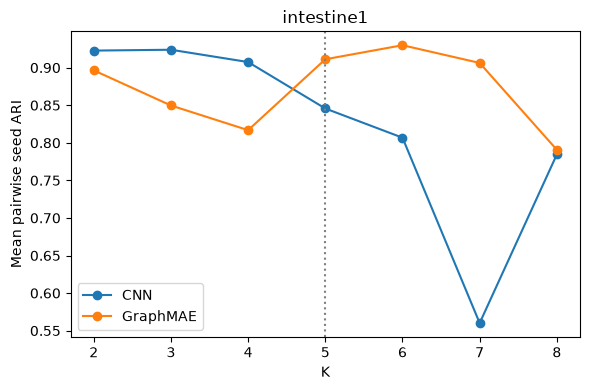

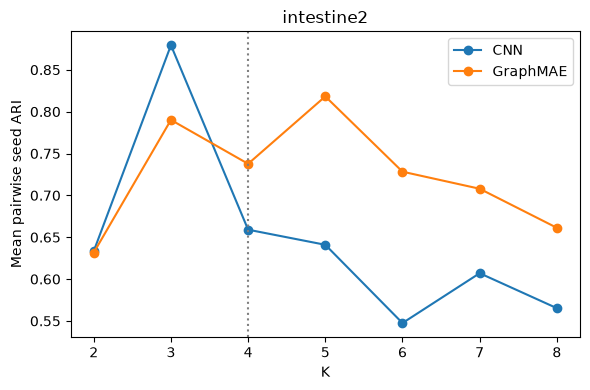

In [13]:
from itertools import combinations
from sklearn.metrics import adjusted_rand_score

k_rows = []
for image in SETTINGS["images"]:
    for method in ("CNN", "GraphMAE"):
        for k in range(2, 9):
            labels_by_seed, fractions = [], []
            for seed in SETTINGS["seeds"]["joint"]:
                embedding = (cnn_results[image, "joint", seed]["features"] if method == "CNN"
                             else graph_results[image, "joint", "graphmae", seed]["embedding"])
                with calculation_threads(2):
                    labels = KMeans(n_clusters=k, **SETTINGS["kmeans"]["joint"]).fit_predict(embedding)
                labels_by_seed.append(labels)
                fractions.append(float(np.bincount(labels, minlength=k).min() / len(labels)))
            agreement = [adjusted_rand_score(a, b) for a, b in combinations(labels_by_seed, 2)]
            k_rows.append({"image": image, "method": method, "K": k,
                           "seed_ARI": float(np.mean(agreement)),
                           "minimum_cluster_fraction": min(fractions)})
k_sweep = pd.DataFrame(k_rows)
display(k_sweep.round(3))
for image in SETTINGS["images"]:
    figure, axis = plt.subplots(figsize=(6, 4))
    for method, group in k_sweep.query("image == @image").groupby("method"):
        axis.plot(group["K"], group["seed_ARI"], "o-", label=method)
    axis.axvline(SETTINGS["images"][image]["k"], color="gray", linestyle=":")
    axis.set(xlabel="K", ylabel="Mean pairwise seed ARI", title=image)
    axis.legend()
    figure.tight_layout()
    plt.show()

## Archived selection records

These tables describe the paper's searches. They are references, separate
from the fresh fits above, and are never used to choose a setting in this run.
Exact published figure source data and plotting code remain in the repository.

In [14]:
for image, config in SETTINGS["images"].items():
    print(image, "— archived independent CNN search")
    display(pd.DataFrame(config["matched_cnn_search_table"])[
        ["architecture_index", "architecture", "eligible", "stability"]
    ])
    for method, records in config["matched_method_search_tables"].items():
        print(method)
        display(pd.DataFrame(records))

intestine1 — archived independent CNN search


,architecture_index,architecture,eligible,stability
0,0,"{'blocks': 2, 'width': 16, 'readout': 'avgpool...",True,0.844429
1,1,"{'blocks': 2, 'width': 16, 'readout': 'avgpool...",True,0.806270
2,2,"{'blocks': 2, 'width': 16, 'readout': 'maxpool...",True,0.804586
3,3,"{'blocks': 2, 'width': 32, 'readout': 'avgpool...",True,0.799381
4,4,"{'blocks': 2, 'width': 32, 'readout': 'avgpool...",True,0.646703
5,5,"{'blocks': 2, 'width': 32, 'readout': 'maxpool...",True,0.838010
6,6,"{'blocks': 3, 'width': 16, 'readout': 'avgpool...",True,0.880796
7,7,"{'blocks': 3, 'width': 16, 'readout': 'avgpool...",True,0.843711
8,8,"{'blocks': 3, 'width': 16, 'readout': 'maxpool...",True,0.745589
9,9,"{'blocks': 3, 'width': 32, 'readout': 'avgpool...",True,0.898692


graphmae


,index,config,completed_seeds,eligible,stability,minimum_cluster_fraction,pairwise_seed_ari,measured_optimizer_iterations
0,0,"{'k': 60, 'depth': 2, 'mask': 0.5}",3,True,0.900088,0.065490,"[0.9021858803094903, 0.9095450150692447, 0.888...",669
1,1,"{'k': 60, 'depth': 2, 'mask': 0.75}",3,True,0.906518,0.070275,"[0.8781865370280558, 0.9056885352001453, 0.935...",646
2,2,"{'k': 60, 'depth': 4, 'mask': 0.5}",3,True,0.890853,0.069154,"[0.878731051435696, 0.9274936892125901, 0.8663...",666
3,3,"{'k': 60, 'depth': 4, 'mask': 0.75}",3,True,0.910390,0.075060,"[0.9489503733270155, 0.8904033723525434, 0.891...",644
4,4,"{'k': 120, 'depth': 2, 'mask': 0.5}",3,True,0.947956,0.061005,"[0.9451250577482357, 0.9478619989837875, 0.950...",633
5,5,"{'k': 120, 'depth': 2, 'mask': 0.75}",3,True,0.929519,0.058762,"[0.9075431928330114, 0.9757825222236489, 0.905...",644
6,6,"{'k': 120, 'depth': 4, 'mask': 0.5}",3,True,0.949173,0.070051,"[0.9328595770466093, 0.9585854787786746, 0.956...",629
7,7,"{'k': 120, 'depth': 4, 'mask': 0.75}",3,True,0.945630,0.062500,"[0.932444195903149, 0.9501182253688436, 0.9543...",631
8,8,"{'k': 240, 'depth': 2, 'mask': 0.5}",3,True,0.954423,0.071471,"[0.9420946421210507, 0.9476763487552119, 0.973...",653
9,9,"{'k': 240, 'depth': 2, 'mask': 0.75}",3,True,0.958212,0.075733,"[0.9487903549244077, 0.9625703838054173, 0.963...",633


banksy


...

,index,config,completed_seeds,eligible,stability,minimum_cluster_fraction,pairwise_seed_ari,measured_optimizer_iterations
0,0,"{'k': 15, 'lambda': 0.2, 'max_m': 1, 'pca': 20}",3,True,0.849904,0.090803,"[0.8206736166719806, 0.8360772398820766, 0.892...",54
1,1,"{'k': 15, 'lambda': 0.4, 'max_m': 1, 'pca': 20}",3,True,0.875258,0.097788,"[0.8636013831760632, 0.8774469688103796, 0.884...",60
2,2,"{'k': 15, 'lambda': 0.6, 'max_m': 1, 'pca': 20}",3,True,0.494437,0.102021,"[0.34977380906033145, 0.7946434350021196, 0.33...",100
3,3,"{'k': 15, 'lambda': 0.8, 'max_m': 1, 'pca': 20}",3,True,0.853838,0.127421,"[0.8821941787794215, 0.8335408493244734, 0.845...",49
4,4,"{'k': 160, 'lambda': 0.2, 'max_m': 1, 'pca': 20}",3,True,0.825697,0.091438,"[0.8001058265364109, 0.7993900345441849, 0.877...",71
5,5,"{'k': 160, 'lambda': 0.4, 'max_m': 1, 'pca': 20}",3,True,0.800564,0.115144,"[0.7603430530113824, 0.7673936739534571, 0.873...",80
6,6,"{'k': 160, 'lambda': 0.6, 'max_m': 1, 'pca': 20}",3,True,0.520035,0.122553,"[0.7901275688810355, 0.3885145237608215, 0.381...",135
7,7,"{'k': 160, 'lambda': 0.8, 'max_m': 1, 'pca': 20}",3,True,0.892430,0.162874,"[0.8925672169810549, 0.9153517155529951, 0.869...",43
8,8,"{'k': 320, 'lambda': 0.2, 'max_m': 1, 'pca': 20}",3,True,0.868922,0.097153,"[0.8535226369128333, 0.8801171240138684, 0.873...",50
9,9,"{'k': 320, 'lambda': 0.4, 'max_m': 1, 'pca': 20}",3,True,0.562864,0.121283,"[0.42385938249407457, 0.4002745659942748, 0.86...",71


utag


,index,config,completed_seeds,eligible,stability,minimum_cluster_fraction,pairwise_seed_ari,measured_optimizer_iterations
0,0,"{'radius_um': 20.0, 'pca': 10, 'normalization'...",3,True,0.858805,0.075564,"[0.8441824603822438, 0.8578409997120764, 0.874...",60.0
1,1,"{'radius_um': 20.0, 'pca': 20, 'normalization'...",3,True,0.857592,0.075775,"[0.8424701855035076, 0.8532963209738686, 0.877...",55.0
2,2,"{'radius_um': 20.0, 'pca': 30, 'normalization'...",3,True,0.847058,0.075987,"[0.8204127054403979, 0.8531354667455661, 0.867...",54.0
3,3,"{'radius_um': 119.56689180399063, 'pca': 10, '...",3,True,0.709393,0.106890,"[0.5864758197571621, 0.6120296022885932, 0.929...",54.0
4,4,"{'radius_um': 119.56689180399063, 'pca': 20, '...",3,True,0.699429,0.100222,"[0.5835573747170795, 0.5992324125114641, 0.915...",50.0
5,5,"{'radius_um': 119.56689180399063, 'pca': 30, '...",3,True,0.711664,0.104032,"[0.5953006282581323, 0.6152180776860053, 0.924...",39.0
6,6,"{'radius_um': 336.45637576578406, 'pca': 10, '...",3,True,0.957715,0.119801,"[0.9698280025928442, 0.9590164613719483, 0.944...",38.0
7,7,"{'radius_um': 336.45637576578406, 'pca': 20, '...",3,True,0.945959,0.118214,"[0.9451336308939908, 0.9689363082865874, 0.923...",100.0
8,8,"{'radius_um': 336.45637576578406, 'pca': 30, '...",3,True,0.945986,0.118214,"[0.9469998255801632, 0.9668246666963765, 0.924...",99.0
9,9,"{'radius_um': 672.9127515315681, 'pca': 10, 'n...",0,False,NaN,NaN,NaN,NaN


cellcharter


,index,config,completed_seeds,eligible,stability,minimum_cluster_fraction,pairwise_seed_ari,measured_optimizer_iterations
0,0,"{'graph': 'native_knn6', 'hops': 1}",3,True,0.765672,0.111123,"[0.7693968224730746, 0.7642904070336229, 0.763...",93
1,1,"{'graph': 'native_knn6', 'hops': 2}",3,True,0.539290,0.093132,"[0.4145515044267269, 0.4153874536013762, 0.787...",109
2,2,"{'graph': 'native_knn6', 'hops': 3}",3,True,0.813286,0.099376,"[0.8098680737263978, 0.8186767895798929, 0.811...",104
3,3,"{'graph': 'mantpy_k80', 'hops': 1}",3,True,0.603589,0.138322,"[0.6159222721315696, 0.6846421399382434, 0.510...",163
4,4,"{'graph': 'mantpy_k80', 'hops': 2}",3,True,0.607307,0.131442,"[0.511289737412769, 0.779705025455414, 0.53092...",198
5,5,"{'graph': 'mantpy_k80', 'hops': 3}",3,True,0.685306,0.116414,"[0.604694257738385, 0.608854105125632, 0.84236...",129
6,6,"{'graph': 'mantpy_k160', 'hops': 1}",3,True,0.630863,0.131654,"[0.5466148170886889, 0.8047763264905482, 0.541...",203
7,7,"{'graph': 'mantpy_k160', 'hops': 2}",3,True,0.636169,0.140967,"[0.5408821072077238, 0.8042620318677035, 0.563...",183
8,8,"{'graph': 'mantpy_k160', 'hops': 3}",3,True,0.762342,0.149116,"[0.7636506418628477, 0.768374413742839, 0.7549...",137
9,9,"{'graph': 'mantpy_k320', 'hops': 1}",3,True,0.615116,0.148164,"[0.49763111946389343, 0.8110166709437944, 0.53...",269


## Export results and measured runtime

Exports contain fresh seed-level scores, summary tables, K-sweep results,
label arrays, feature arrays, training losses, settings and stage times.
Re-running this notebook verifies checkpoint identities before reusing fits.
Differences across hardware/software can affect nearest-neighbour ties and
stochastic training; exact deposited paper scores remain available as source data.

In [15]:
scores, summary = score_summary(score_rows)
scores.to_csv(RESULTS / "scores.csv", index=False)
summary.to_csv(RESULTS / "score_summary.csv", index=False)
k_sweep.to_csv(RESULTS / "k_sweep.csv", index=False)
write_json(RESULTS / "settings.json", SETTINGS)
timings = pd.concat([
    store.save_timing().assign(image=image) for image, store in stores.items()
], ignore_index=True)
timings.to_csv(RESULTS / "timings.csv", index=False)
measured_seconds = time.perf_counter() - NOTEBOOK_STARTED
write_json(RESULTS / "run_summary.json", {
    "notebook_seconds": measured_seconds,
    "completed_fit_seconds": float(timings["seconds"].sum()),
    "reused_stages": int(timings["reused"].sum()),
    "completed_stages": len(timings),
    "environment": environment(),
    "configuration_searches": 0,
})
display(timings.groupby(["image", "arm"])["seconds"].sum().to_frame())
print(f"Notebook elapsed: {measured_seconds / 60:.1f} min")
print("Outputs:", RESULTS.resolve())

seconds
image      arm                      
intestine1 defaults        23.094050
           intensity        7.418557
           joint          761.837452
           matched        288.598103
           supplementary   95.477833
intestine2 defaults        26.504410
           intensity        4.235387
           joint          501.382102
           matched        213.079774
           supplementary   89.556388

Notebook elapsed: 37.5 min
Outputs: .\outputs\notebook_api_implementation\full_after\workspaces\intestine\results\intestine
